# Лабораторная 1. MLP, статистики Pokémon

Предсказываем `base_experience`. Данные: `pokemon_complete_stats.csv`.
https://www.kaggle.com/datasets/shreyashautomation/pokemon-stats-dataset



In [7]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_PATH = Path("pokemon_complete_stats.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("lab1") / "pokemon_complete_stats.csv"


## 1. Данные

In [8]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
display(raw.head())
display(raw.isna().sum().to_frame("пропуски"))
display(raw.describe().T.round(2))


(1351, 20)


,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense,special_attack,special_defense,speed,abilities,generation,is_legendary,is_mythical,color,shape,capture_rate
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49,65,65,45,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63,80,80,60,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83,100,100,80,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
3,4,charmander,6,85,62.0,fire,NaN,39,52,43,60,50,65,"blaze, solar-power",generation-i,False,False,red,upright,45
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58,80,65,80,"blaze, solar-power",generation-i,False,False,red,upright,45


,пропуски
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


,count,mean,std,min,25%,50%,75%,max
id,1351.0,2841.69,4139.02,1.0,338.5,676.0,1013.5,10326.0
height_dm,1351.0,20.44,53.24,1.0,6.0,11.0,17.0,1000.0
weight_hg,1351.0,991.06,1953.12,0.0,94.5,326.0,853.5,10000.0
base_experience,1302.0,161.94,82.53,36.0,71.0,165.0,222.5,608.0
hp,1351.0,71.67,26.83,1.0,55.0,70.0,85.0,255.0
attack,1351.0,82.76,32.35,5.0,60.0,80.0,102.5,190.0
defense,1351.0,76.19,30.71,5.0,55.0,70.0,95.0,250.0
special_attack,1351.0,75.42,34.03,10.0,50.0,69.0,97.0,216.0
special_defense,1351.0,74.12,27.80,20.0,54.0,70.0,90.0,250.0
speed,1351.0,72.00,30.64,5.0,49.0,70.0,95.0,200.0


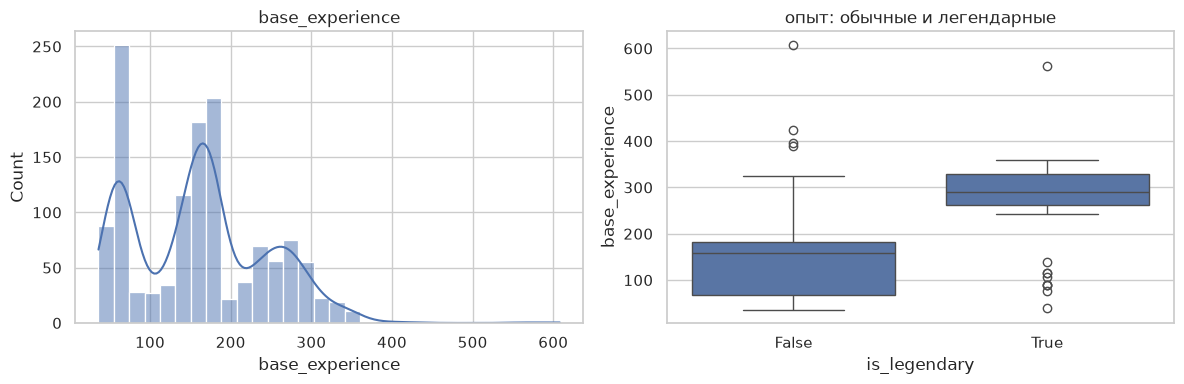

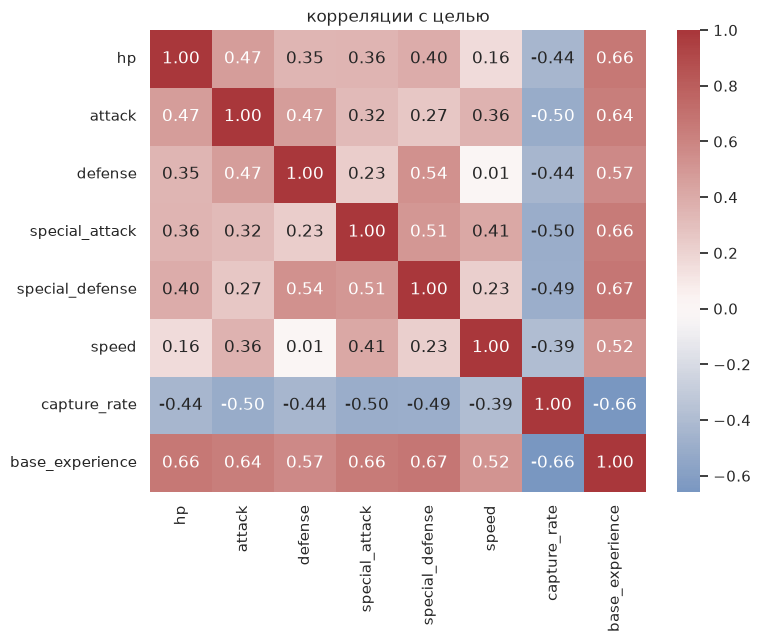

base_experience    1.000
special_defense    0.673
hp                 0.664
special_attack     0.656
attack             0.635
defense            0.568
speed              0.520
capture_rate      -0.659
Name: base_experience, dtype: float64
средний опыт legendary: {False: 149.8, True: 284.0}


In [9]:
eda = raw.dropna(subset=["base_experience"]).copy()
numeric = ["hp", "attack", "defense", "special_attack", "special_defense", "speed", "capture_rate", "base_experience"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eda["base_experience"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("base_experience")
sns.boxplot(data=eda, x="is_legendary", y="base_experience", ax=axes[1])
axes[1].set_title("опыт: обычные и легендарные")
plt.tight_layout()
plt.show()

corr = eda[numeric].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("корреляции с целью")
plt.show()

print(corr["base_experience"].sort_values(ascending=False).round(3))
print("средний опыт legendary:", eda.groupby("is_legendary")["base_experience"].mean().round(1).to_dict())


С опытом сильнее всего связаны спецзащита, HP, спец-атака и атака (корреляция около 0.64–0.67). `capture_rate` связан отрицательно. Легендарные в среднем заметно опытнее. У цели 49 пропусков — эти строки выкидываем. Пустой `type_2` — это «второго типа нет», не ошибка. Рост и вес скошены, перед обучением берём `log1p`.

## 2. Train / valid / test

- **train** — по нему шагает оптимизатор
- **valid** — по нему выбираем эпоху и сравниваем глубину/ширину
- **test** — один раз в конце, в выборе модели не участвует

Доли 70 / 15 / 15. Scaler и one-hot учим только на train.


In [10]:
TARGET = "base_experience"
NUMERIC = ["height_dm", "weight_hg", "hp", "attack", "defense", "special_attack", "special_defense", "speed", "capture_rate", "n_abilities", "is_legendary", "is_mythical"]
CATEGORICAL = ["type_1", "type_2", "generation", "color", "shape"]
TEST_SIZE = 0.15
VALID_SIZE = 0.15

frame = raw.dropna(subset=[TARGET]).copy()
frame["type_2"] = frame["type_2"].fillna("none")
frame["n_abilities"] = frame["abilities"].fillna("").map(lambda text: 0 if str(text).strip() == "" else len([part for part in str(text).split(",") if part.strip()]))
frame["is_legendary"] = frame["is_legendary"].astype(int)
frame["is_mythical"] = frame["is_mythical"].astype(int)
frame["height_dm"] = np.log1p(frame["height_dm"])
frame["weight_hg"] = np.log1p(frame["weight_hg"])

names = frame["name"].to_numpy()
y = frame[TARGET].to_numpy(dtype=np.float64)
x = frame[NUMERIC + CATEGORICAL]

x_trainval, x_test, y_trainval, y_test, names_trainval, names_test = train_test_split(
    x, y, names, test_size=TEST_SIZE, random_state=SEED
)
x_train, x_valid, y_train, y_valid, _, _ = train_test_split(
    x_trainval, y_trainval, names_trainval,
    test_size=VALID_SIZE / (1 - TEST_SIZE),
    random_state=SEED,
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
x_train = preprocessor.fit_transform(x_train).astype(np.float32)
x_valid = preprocessor.transform(x_valid).astype(np.float32)
x_test = preprocessor.transform(x_test).astype(np.float32)

y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel().astype(np.float32)
y_valid = y_scaler.transform(y_valid.reshape(-1, 1)).ravel().astype(np.float32)
y_test = y_scaler.transform(y_test.reshape(-1, 1)).ravel().astype(np.float32)

feature_names = NUMERIC + preprocessor.named_transformers_["cat"].get_feature_names_out(CATEGORICAL).tolist()
n_total = len(y_train) + len(y_valid) + len(y_test)
print(f"признаков: {x_train.shape[1]}")
print(f"train={len(y_train)} ({len(y_train)/n_total:.0%}), valid={len(y_valid)} ({len(y_valid)/n_total:.0%}), test={len(y_test)} ({len(y_test)/n_total:.0%})")


def to_experience(y_scaled):
    return y_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()




признаков: 82
train=910 (70%), valid=196 (15%), test=196 (15%)


## 3. MLP

`hidden_sizes` задаёт ширину каждого скрытого слоя. Длина списка — глубина. Dropout и weight decay нулевые, чтобы на кривых было видно переобучение. Эпоха с минимальным valid MSE сохраняется отдельно и идёт в test.


In [ ]:
class MLP(nn.Module):
    def __init__(self, in_features, hidden_sizes, activation=nn.ReLU, dropout=0.0):
        super().__init__()
        layers = []
        previous = in_features
        for width in hidden_sizes:
            layers += [nn.Linear(previous, width), activation()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_model(x_tr, y_tr, x_va, y_va, hidden_sizes, epochs=80, lr=1e-3, batch_size=64, seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = MLP(x_tr.shape[1], hidden_sizes)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_loader = DataLoader(TensorDataset(torch.tensor(x_tr), torch.tensor(y_tr)), batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(TensorDataset(torch.tensor(x_va), torch.tensor(y_va)), batch_size=batch_size)

    history = []
    best_state = copy.deepcopy(model.state_dict())
    best_epoch, best_valid = 0, float("inf")
    for epoch in range(epochs):
        model.train()
        total, count = 0.0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += float(loss.detach()) * len(xb)
            count += len(xb)
        model.eval()
        with torch.no_grad():
            vtotal, vcount = 0.0, 0
            for xb, yb in valid_loader:
                vloss = loss_fn(model(xb), yb)
                vtotal += float(vloss) * len(xb)
                vcount += len(xb)
        train_loss, valid_loss = total / count, vtotal / vcount
        history.append({"epoch": epoch, "train": train_loss, "valid": valid_loss})
        if valid_loss < best_valid:
            best_valid, best_epoch = valid_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
    return model, history, best_state, best_epoch


@torch.no_grad()
def predict(model, features):
    model.eval()
    return model(torch.tensor(features)).numpy()


def metrics(y_true_scaled, y_pred_scaled):
    y_true, y_pred = to_experience(y_true_scaled), to_experience(y_pred_scaled)
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": r2_score(y_true, y_pred),
    }


## 4. Обучение базовой сети и переобучение

параметров: 9537
лучшая эпоха по valid: 33
последняя эпоха  train RMSE=4.47  valid RMSE=26.94  зазор=22.47
чекпоинт valid  RMSE=25.83  MAE=17.95  R2=0.904
test            RMSE=24.59  MAE=17.46  R2=0.900


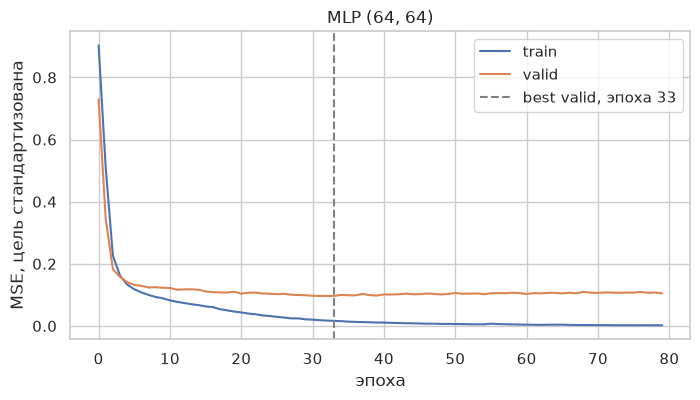

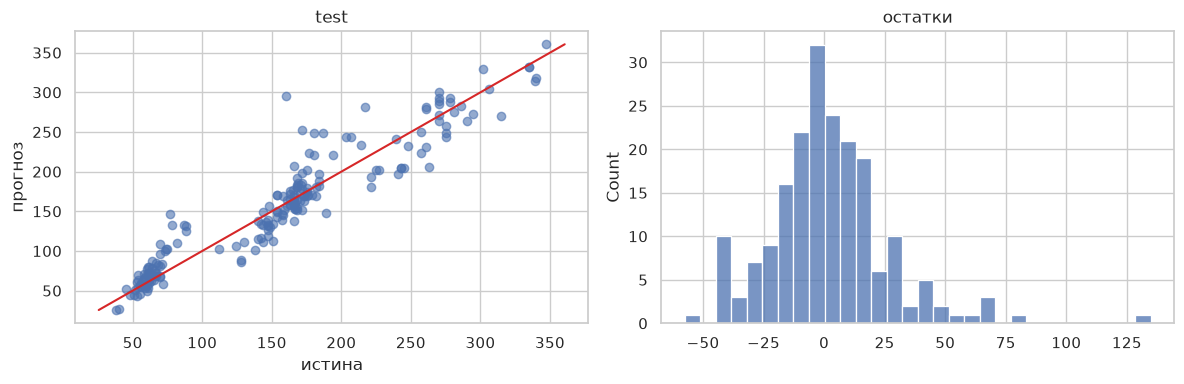

In [12]:
HIDDEN = (64, 64)
model, history, best_state, best_epoch = train_model(x_train, y_train, x_valid, y_valid, HIDDEN)

last_train = metrics(y_train, predict(model, x_train))
last_valid = metrics(y_valid, predict(model, x_valid))
model.load_state_dict(best_state)
best_valid = metrics(y_valid, predict(model, x_valid))
test_metrics = metrics(y_test, predict(model, x_test))

print(f"параметров: {sum(p.numel() for p in model.parameters())}")
print(f"лучшая эпоха по valid: {best_epoch}")
print(f"последняя эпоха  train RMSE={last_train['rmse']:.2f}  valid RMSE={last_valid['rmse']:.2f}  зазор={last_valid['rmse'] - last_train['rmse']:.2f}")
print(f"чекпоинт valid  RMSE={best_valid['rmse']:.2f}  MAE={best_valid['mae']:.2f}  R2={best_valid['r2']:.3f}")
print(f"test            RMSE={test_metrics['rmse']:.2f}  MAE={test_metrics['mae']:.2f}  R2={test_metrics['r2']:.3f}")

epochs = [row["epoch"] for row in history]
plt.figure(figsize=(8, 4))
plt.plot(epochs, [row["train"] for row in history], label="train")
plt.plot(epochs, [row["valid"] for row in history], label="valid")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"best valid, эпоха {best_epoch}")
plt.xlabel("эпоха")
plt.ylabel("MSE, цель стандартизована")
plt.title(f"MLP {HIDDEN}")
plt.legend()
plt.show()

y_true = to_experience(y_test)
y_hat = to_experience(predict(model, x_test))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_true, y_hat, alpha=0.6)
limits = [min(y_true.min(), y_hat.min()), max(y_true.max(), y_hat.max())]
axes[0].plot(limits, limits, color="tab:red")
axes[0].set_xlabel("истина")
axes[0].set_ylabel("прогноз")
axes[0].set_title("test")
sns.histplot(y_hat - y_true, bins=30, ax=axes[1])
axes[1].set_title("остатки")
plt.tight_layout()
plt.show()


Зазор на последней эпохе большой: train RMSE сильно ниже valid. Сеть запомнила обучающие объекты. В test идут веса эпохи с минимальным valid, она отмечена пунктиром.

## 5. Глубина и ширина

Та же функция `train_model`. Меняется только `hidden_sizes`. Сравниваем с базой `(64, 64)` по valid RMSE. Test печатаем, но архитектуру по нему не выбираем.


(16, 16) valid=28.72 gap=17.13
(32, 32) valid=26.98 gap=21.26
(64, 64) valid=25.83 gap=22.47
(128, 128) valid=25.60 gap=23.93
(256, 256) valid=25.19 gap=24.29
(64,) valid=26.60 gap=18.96
(64, 64) valid=25.83 gap=22.47
(64, 64, 64) valid=25.20 gap=24.55
(64, 64, 64, 64) valid=25.77 gap=24.30
(64, 64, 64, 64, 64, 64) valid=25.33 gap=23.85


,hidden,depth,width,params,best_epoch,train_rmse,valid_rmse_last,gap,valid_rmse,test_rmse
0,"(16, 16)",2,16,1617,28,13.42,30.55,17.13,28.72,24.76
1,"(32, 32)",2,32,3745,52,7.30,28.56,21.26,26.98,26.22
2,"(64, 64)",2,64,9537,33,4.47,26.94,22.47,25.83,24.59
3,"(128, 128)",2,128,27265,28,2.40,26.33,23.93,25.60,22.19
4,"(256, 256)",2,256,87297,15,2.77,27.05,24.29,25.19,22.18


,hidden,depth,width,params,best_epoch,train_rmse,valid_rmse_last,gap,valid_rmse,test_rmse
0,"(64,)",1,64,5377,41,8.17,27.14,18.96,26.60,24.12
1,"(64, 64)",2,64,9537,33,4.47,26.94,22.47,25.83,24.59
2,"(64, 64, 64)",3,64,13697,26,3.21,27.76,24.55,25.20,24.21
3,"(64, 64, 64, 64)",4,64,17857,39,2.69,26.99,24.30,25.77,25.05
4,"(64, 64, 64, 64, 64, 64)",6,64,26177,22,2.85,26.71,23.85,25.33,24.63


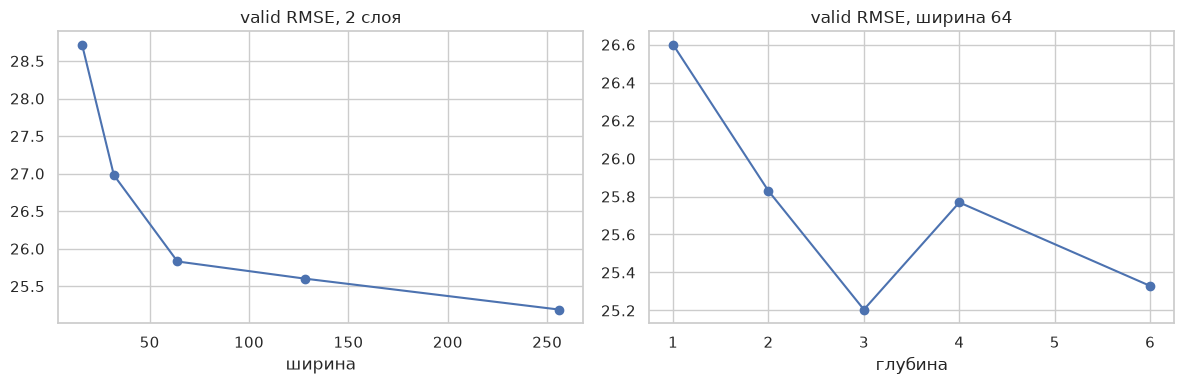

база (64, 64): valid 25.83, test 24.59
лучшая ширина (256, 256): valid 25.19, test 22.18
лучшая глубина (64, 64, 64): valid 25.20, test 24.21


In [13]:
def run(hidden_sizes):
    trained, hist, state, epoch = train_model(x_train, y_train, x_valid, y_valid, hidden_sizes)
    last_tr = metrics(y_train, predict(trained, x_train))
    last_va = metrics(y_valid, predict(trained, x_valid))
    trained.load_state_dict(state)
    row = {
        "hidden": str(hidden_sizes),
        "depth": len(hidden_sizes),
        "width": hidden_sizes[0],
        "params": sum(p.numel() for p in trained.parameters()),
        "best_epoch": epoch,
        "train_rmse": last_tr["rmse"],
        "valid_rmse_last": last_va["rmse"],
        "gap": last_va["rmse"] - last_tr["rmse"],
        "valid_rmse": metrics(y_valid, predict(trained, x_valid))["rmse"],
        "test_rmse": metrics(y_test, predict(trained, x_test))["rmse"],
    }
    print(hidden_sizes, f"valid={row['valid_rmse']:.2f}", f"gap={row['gap']:.2f}")
    return row

width_rows = [run((width, width)) for width in (16, 32, 64, 128, 256)]
depth_rows = [run(tuple([64] * depth)) for depth in (1, 2, 3, 4, 6)]
width_df = pd.DataFrame(width_rows)
depth_df = pd.DataFrame(depth_rows)
display(width_df.round(2))
display(depth_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(width_df["width"], width_df["valid_rmse"], marker="o")
axes[0].set_title("valid RMSE, 2 слоя")
axes[0].set_xlabel("ширина")
axes[1].plot(depth_df["depth"], depth_df["valid_rmse"], marker="o")
axes[1].set_title("valid RMSE, ширина 64")
axes[1].set_xlabel("глубина")
plt.tight_layout()
plt.show()

base = width_df.loc[width_df["hidden"] == str(HIDDEN)].iloc[0]
best_w = width_df.loc[width_df["valid_rmse"].idxmin()]
best_d = depth_df.loc[depth_df["valid_rmse"].idxmin()]
print(f"база {base['hidden']}: valid {base['valid_rmse']:.2f}, test {base['test_rmse']:.2f}")
print(f"лучшая ширина {best_w['hidden']}: valid {best_w['valid_rmse']:.2f}, test {best_w['test_rmse']:.2f}")
print(f"лучшая глубина {best_d['hidden']}: valid {best_d['valid_rmse']:.2f}, test {best_d['test_rmse']:.2f}")


Шире сеть — ниже train RMSE и больше зазор с valid. Слишком узкая сеть хуже и на valid. Глубина после трёх слоёв ширины 64 valid почти не улучшает: лишние слои в основном запоминают train. База `(64, 64)` — точка на этих кривых, не отдельный эксперимент.

## 6. Градиенты одного объекта по слоям

Берём один покемон из test. Forward, MSE с истинной целью, backward. Для каждого `Linear` — норма градиента выхода, веса и смещения.


rotom
истина 154.0, прогноз 142.5


,layer,dL/dz,dL/dW,dL/db
0,net.0,0.3643,1.5569,0.3643
1,net.2,0.2223,0.4020,0.2223
2,net.4,0.2769,0.3947,0.2769


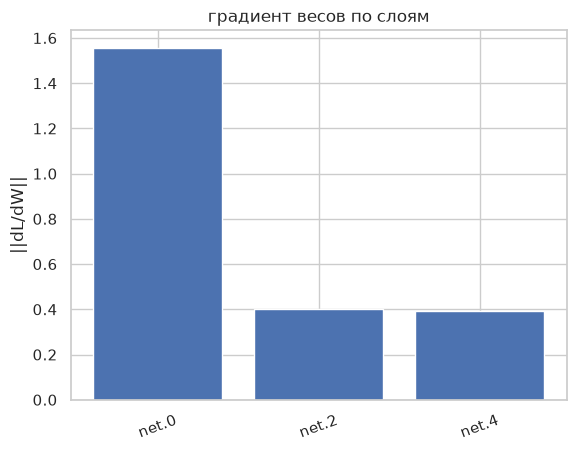

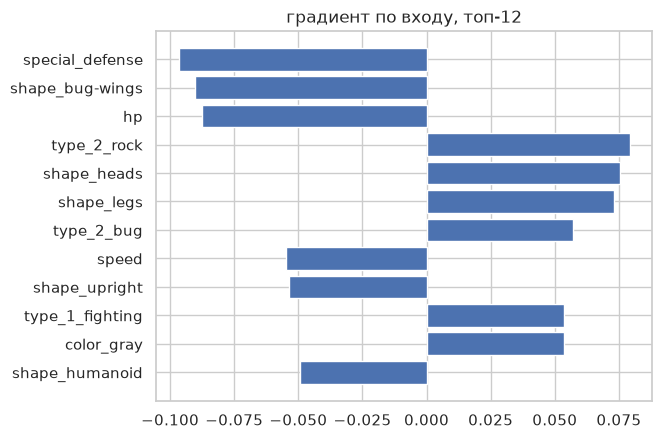

In [14]:
index = 0
sample_x = torch.tensor(x_test[index:index + 1], dtype=torch.float32, requires_grad=True)
sample_y = torch.tensor(y_test[index:index + 1], dtype=torch.float32)

grads = {}
hooks = []
for name, module in model.named_modules():
    if isinstance(module, nn.Linear):
        def hook(module, grad_input, grad_output, layer_name=name):
            grads[layer_name] = grad_output[0].detach()
        hooks.append(module.register_full_backward_hook(hook))

model.eval()
model.zero_grad()
prediction = model(sample_x)
loss = nn.MSELoss()(prediction, sample_y)
loss.backward()
for hook in hooks:
    hook.remove()

rows = []
for name, module in model.named_modules():
    if isinstance(module, nn.Linear):
        rows.append({
            "layer": name,
            "dL/dz": float(grads[name].norm()),
            "dL/dW": float(module.weight.grad.norm()),
            "dL/db": float(module.bias.grad.norm()),
        })
print(names_test[index])
print(f"истина {to_experience(y_test[index:index+1])[0]:.1f}, прогноз {to_experience(prediction.detach().numpy())[0]:.1f}")
display(pd.DataFrame(rows).round(4))

plt.bar([row["layer"] for row in rows], [row["dL/dW"] for row in rows])
plt.ylabel("||dL/dW||")
plt.title("градиент весов по слоям")
plt.xticks(rotation=20)
plt.show()

order = np.argsort(np.abs(sample_x.grad.numpy().ravel()))[::-1][:12]
top_names = np.array(feature_names)[order]
top_values = sample_x.grad.numpy().ravel()[order]
plt.barh(top_names[::-1], top_values[::-1])
plt.title("градиент по входу, топ-12")
plt.show()


## 7. Функции активации

Свои реализации на NumPy. Каждая возвращает массив значений.


In [15]:
def sigmoid(z):
    z = np.asarray(z, dtype=np.float64)
    out = np.empty_like(z)
    positive = z >= 0
    out[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    out[~positive] = exp_z / (1 + exp_z)
    return out

def tanh(z):
    return np.tanh(np.asarray(z, dtype=np.float64))

def relu(z):
    return np.maximum(np.asarray(z, dtype=np.float64), 0)

def leaky_relu(z, alpha=0.01):
    z = np.asarray(z, dtype=np.float64)
    return np.where(z >= 0, z, alpha * z)
n 
def elu(z, alpha=1.0):
    z = np.asarray(z, dtype=np.float64)
    return np.where(z >= 0, z, alpha * (np.exp(np.clip(z, -60, None)) - 1))

def softplus(z):
    z = np.asarray(z, dtype=np.float64)
    return np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)

def silu(z):
    z = np.asarray(z, dtype=np.float64)
    return z * sigmoid(z)

def gelu(z):
    z = np.asarray(z, dtype=np.float64)
    return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3)))

def mish(z):
    z = np.asarray(z, dtype=np.float64)
    return z * np.tanh(softplus(z))

def softmax(z, axis=-1):
    z = np.asarray(z, dtype=np.float64)
    shifted = z - np.max(z, axis=axis, keepdims=True)
    exp = np.exp(shifted)
    return exp / exp.sum(axis=axis, keepdims=True)

functions = {
    "sigmoid": sigmoid, "tanh": tanh, "relu": relu, "leaky_relu": leaky_relu,
    "elu": elu, "softplus": softplus, "silu": silu, "gelu": gelu, "mish": mish,
}
z = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for ax, (name, fn) in zip(axes.ravel(), functions.items()):
    ax.plot(z, fn(z))
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("sigmoid(0) =", float(sigmoid(0)))
print("relu([-1, 2]) =", relu(np.array([-1.0, 2.0])))
probs = softmax(np.array([1.0, 2.0, 3.0]))
print("softmax([1, 2, 3]) =", np.round(probs, 4), "сумма", round(float(probs.sum()), 6))


NameError: name 'n' is not defined